# Multi Criteria Decision Analysis on Clusters

## Fuzzy Logic

In [1]:
import numpy as np
import pandas as pd
from func import*

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

In [3]:
pip install scikit-learn

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.0 MB 4.2 MB/s eta 0:00:03
   ------- -------------------------------- 2.1/11.0 MB 5.3 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/11.0 MB 5.9 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/11.0 MB 6.3 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.0 MB 6.3 MB/s eta 0:00:01
   --------------------------- ------------ 7.6/11.0 MB 6.4 MB/s eta 0:00:01
   --------------------------------- ------ 9.2/11.0 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------  10.7/11.0 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 6.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


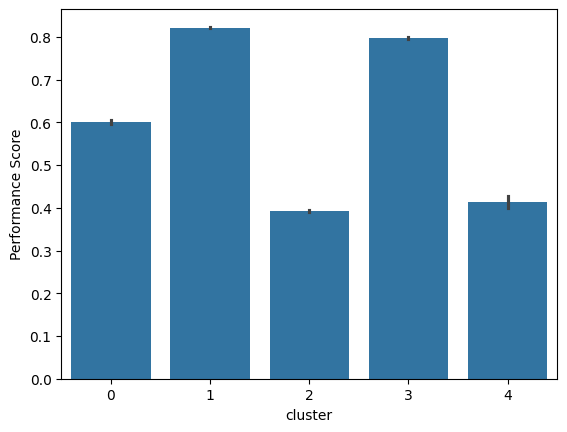

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import skfuzzy as fuzz
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for fuzzy logic
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Perform multi-criteria decision analysis using fuzzy logic
num_clusters = len(X_clustered['cluster'].unique())

# Calculate the membership values for each criterion
membership_matrices = []
for criterion in criteria:
    data = X_clustered[criterion].values
    membership_matrix = fuzz.gaussmf(data, np.mean(data), np.std(data))
    membership_matrices.append(membership_matrix)

# Transpose the membership matrices to match the shape of the weights
membership_matrices = np.transpose(membership_matrices)

# Calculate the performance scores for each cluster
performance_scores = np.dot(membership_matrices, weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Performance Score', ascending=False)

# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Performance Score', data=X_clustered_sorted)

# Show the sorted clustered data
X_clustered_sorted.head()

# Save the clustered data with performance scores to a CSV file
X_clustered_sorted.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/analysis_NBI_GPT.csv')


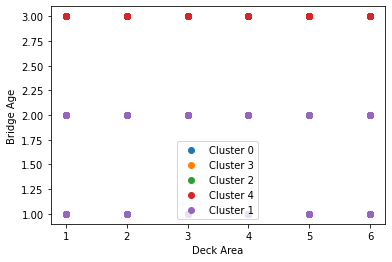

In [18]:
import matplotlib.pyplot as plt

# Plotting the clusters
for cluster in X_clustered_sorted['cluster'].unique():
    cluster_data = X_clustered_sorted[X_clustered_sorted['cluster'] == cluster]
    plt.scatter(cluster_data['Deck_Area'], cluster_data['Bridge_Age'], label=f'Cluster {cluster}')

plt.xlabel('Deck Area')
plt.ylabel('Bridge Age')
plt.legend()
plt.show()


## Analytic Hierarchy Process (AHP)

Please provide the pairwise comparison value between 'Deck_Area' and 'Bridge_Age': 
5


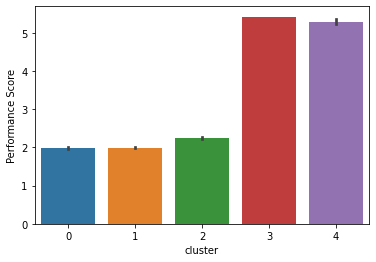

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from func import *
from scipy.linalg import eig
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria and weights for AHP
criteria = ['Deck_Area', 'Bridge_Age']
weights = [1, 1]

# Perform multi-criteria decision analysis using AHP
num_criteria = len(criteria)
num_clusters = len(X_clustered['cluster'].unique())

# Create a matrix to store the pairwise comparison values
comparison_matrix = np.zeros((num_criteria, num_criteria))

# Calculate the pairwise comparison values based on subjective judgments
for i in range(num_criteria):
    for j in range(i + 1, num_criteria):
        print(f"Please provide the pairwise comparison value between '{criteria[i]}' and '{criteria[j]}': ")
        comparison_matrix[i, j] = float(input())
        comparison_matrix[j, i] = 1 / comparison_matrix[i, j]

# Calculate the priority vector using the eigenvector method
eigenvalues, eigenvectors = eig(comparison_matrix)
priority_vector = np.real(eigenvectors[:, np.argmax(eigenvalues)])

# Normalize the priority vector to obtain the criteria weights
criteria_weights = priority_vector / np.sum(priority_vector)
criteria_weights *= weights

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], criteria_weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Performance Score', ascending=False)

# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Performance Score', data=X_clustered_sorted)

# Show the sorted clustered data
X_clustered_sorted.head()

# Save the clustered data with performance scores to a CSV file
X_clustered_sorted.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/analysis_NBI_GPT.csv')


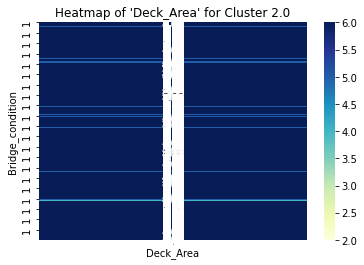

In [4]:
# Find the cluster with the highest performance score
highest_score_cluster = X_clustered_sorted.iloc[0]['cluster']

# Filter the data for the cluster with the highest score
highest_score_cluster_data = X[X_clustered['cluster'] == highest_score_cluster]

# Plot the heatmap of 'Deck_Area' for the highest score cluster
sns.heatmap(highest_score_cluster_data[['Deck_Area']], cmap='YlGnBu', annot=True, fmt='.2f')
plt.title(f"Heatmap of 'Deck_Area' for Cluster {highest_score_cluster}")
plt.show()


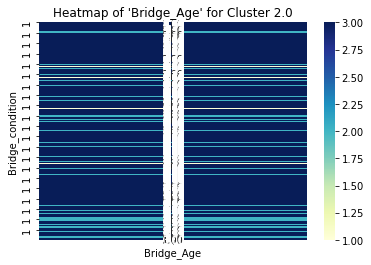

In [5]:
# Plot the heatmap of 'Bridge_Age' for the highest score cluster
sns.heatmap(highest_score_cluster_data[['Bridge_Age']], cmap='YlGnBu', annot=True, fmt='.2f')
plt.title(f"Heatmap of 'Bridge_Age' for Cluster {highest_score_cluster}")
plt.show()


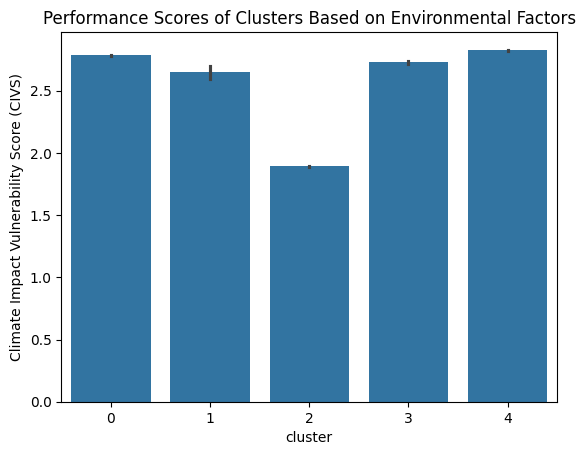

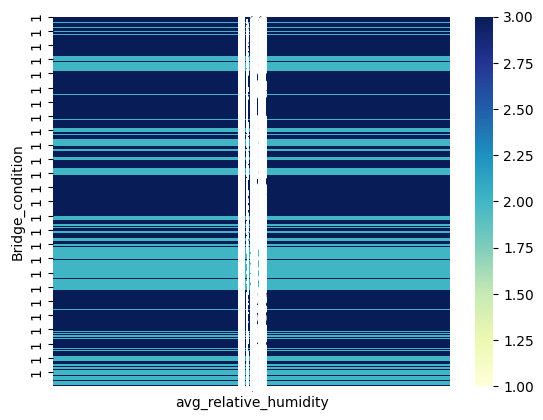

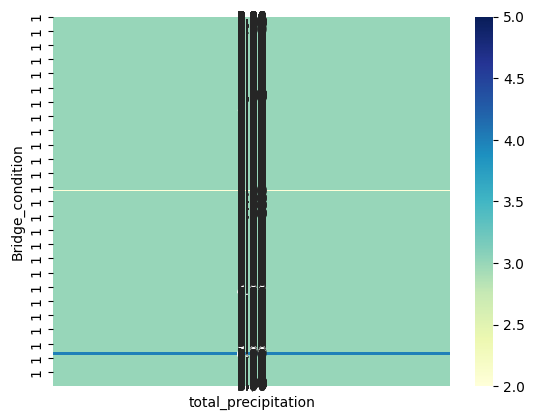

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from func import *
from scipy.linalg import eig
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Load dataset
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

# Drop unnecessary column
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria (Environmental Factors) and weights for AHP
criteria = ['avg_relative_humidity', 'total_precipitation']
weights = [1, 1]  # Adjust the weights if necessary, currently equal importance

# Perform multi-criteria decision analysis using AHP
num_criteria = len(criteria)
num_clusters = len(X_clustered['cluster'].unique())

# Create a matrix to store the pairwise comparison values
comparison_matrix = np.ones((num_criteria, num_criteria))  # Initialize with ones on the diagonal

# Ask for pairwise comparison if needed
# Example assumes equal importance between 'avg_relative_humidity' and 'total_precipitation'
comparison_matrix[0, 1] = 1  # 'avg_relative_humidity' compared to 'total_precipitation'
comparison_matrix[1, 0] = 1 / comparison_matrix[0, 1]  # Inverse comparison

# Calculate the priority vector using the eigenvector method
eigenvalues, eigenvectors = eig(comparison_matrix)
priority_vector = np.real(eigenvectors[:, np.argmax(eigenvalues)])

# Normalize the priority vector to obtain the criteria weights
criteria_weights = priority_vector / np.sum(priority_vector)
criteria_weights *= weights

# Calculate the performance scores for each cluster based on environmental factors
performance_scores = np.dot(X_clustered[criteria], criteria_weights)

# Add the performance scores to the clustered data
X_clustered['Climate Impact Vulnerability Score (CIVS)'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Climate Impact Vulnerability Score (CIVS)', ascending=False)

# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Climate Impact Vulnerability Score (CIVS)', data=X_clustered_sorted)
plt.title('Performance Scores of Clusters Based on Environmental Factors')
plt.show()

# Show the sorted clustered data
X_clustered_sorted.head()

# Save the clustered data with performance scores to a CSV file
X_clustered_sorted.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/analysis_NBI_GPT_environmental.csv')

# Find the cluster with the highest performance score
highest_score_cluster = X_clustered_sorted.iloc[0]['cluster']

# Filter the data for the cluster with the highest score
highest_score_cluster_data = X[X_clustered['cluster'] == highest_score_cluster]

# Plot the heatmap of 'avg_relative_humidity' for the highest score cluster
sns.heatmap(highest_score_cluster_data[['avg_relative_humidity']], cmap='YlGnBu', annot=True, fmt='.2f')
plt.show()

# Plot the heatmap of 'total_precipitation' for the highest score cluster
sns.heatmap(highest_score_cluster_data[['total_precipitation']], cmap='YlGnBu', annot=True, fmt='.2f')
plt.show()


Please provide the pairwise comparison value between 'Deck_Area' and 'Bridge_Age': 
7


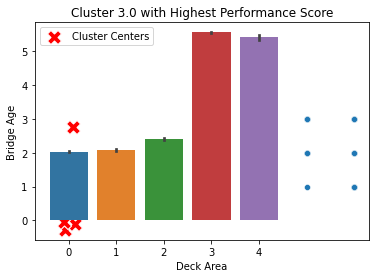

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
from func import *
from scipy.linalg import eig
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria and weights for AHP
criteria = ['Deck_Area', 'Bridge_Age']
weights = [1, 1]

# Perform multi-criteria decision analysis using AHP
num_criteria = len(criteria)
num_clusters = len(X_clustered['cluster'].unique())

# Create a matrix to store the pairwise comparison values
comparison_matrix = np.zeros((num_criteria, num_criteria))

# Calculate the pairwise comparison values based on subjective judgments
for i in range(num_criteria):
    for j in range(i + 1, num_criteria):
        print(f"Please provide the pairwise comparison value between '{criteria[i]}' and '{criteria[j]}': ")
        comparison_matrix[i, j] = float(input())
        comparison_matrix[j, i] = 1 / comparison_matrix[i, j]

# Calculate the priority vector using the eigenvector method
eigenvalues, eigenvectors = eig(comparison_matrix)
priority_vector = np.real(eigenvectors[:, np.argmax(eigenvalues)])

# Normalize the priority vector to obtain the criteria weights
criteria_weights = priority_vector / np.sum(priority_vector)
criteria_weights *= weights

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], criteria_weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Performance Score', ascending=False)

# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Performance Score', data=X_clustered_sorted)

# Show the sorted clustered data
X_clustered_sorted.head()

# Save the clustered data with performance scores to a CSV file
X_clustered_sorted.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/analysis_NBI_GPT.csv')

# Find the cluster with the highest performance score
highest_score_cluster = X_clustered_sorted.iloc[0]['cluster']

# Filter the data to select only the data points from the cluster with the highest score
highest_score_data = X_clustered[X_clustered['cluster'] == highest_score_cluster]

# Visualize the cluster with the highest performance score
sns.scatterplot(x='Deck_Area', y='Bridge_Age', data=highest_score_data)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], s=200, color='red', marker='X', label='Cluster Centers')
plt.xlabel('Deck Area')
plt.ylabel('Bridge Age')
plt.title(f'Cluster {highest_score_cluster} with Highest Performance Score')
plt.legend()
plt.show()


Please provide the pairwise comparison value between level 1 of 'Deck_Area' and level 3 of 'Bridge_Age': 
7


,mainspanmaterial_re,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation,cluster,Performance Score
Bridge_condition,,,,,,,,,,,,
1,2,2,3,1,1,1,1,1,3,3,4,1.0
1,10,1,3,1,1,1,8,1,2,3,0,1.0
1,9,2,3,1,1,1,5,1,2,3,0,1.0
1,8,2,3,1,1,1,5,4,2,3,0,1.0
1,8,2,3,1,1,1,1,4,2,3,0,1.0


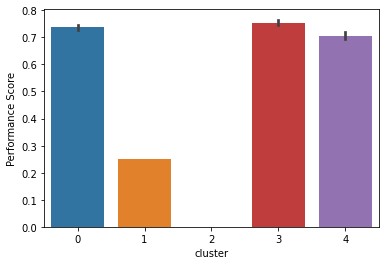

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
from func import *
from scipy.linalg import eig
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# ... (Code for data preprocessing, clustering, and standardization) ...

# ... (Code for data preprocessing, clustering, and standardization) ...

# Define the criteria for AHP
criteria = ['Deck_Area', 'Bridge_Age']
weights = [1, 1]

# Calculate the pairwise comparison value between level 2 of 'Deck_Area' and level 1 of 'Bridge_Age'
print("Please provide the pairwise comparison value between level 1 of 'Deck_Area' and level 3 of 'Bridge_Age': ")
comparison_value = float(input())

# Calculate the inverse value for the opposite comparison
inverse_comparison_value = 1 / comparison_value

# Create a matrix to store the pairwise comparison values for the levels
comparison_matrix_levels = np.array([[1, comparison_value],
                                     [inverse_comparison_value, 1]])

# Normalize the matrix to obtain the level weights
level_weights_deck_area = comparison_matrix_levels.sum(axis=1) / comparison_matrix_levels.sum()
level_weights_bridge_age = comparison_matrix_levels.sum(axis=0) / comparison_matrix_levels.sum()

# Calculate the performance scores for each cluster
performance_scores_deck_area = X['Deck_Area'].map(dict(enumerate(level_weights_deck_area, start=1)))
performance_scores_bridge_age = X['Bridge_Age'].map(dict(enumerate(level_weights_bridge_age, start=3)))
performance_scores = weights[0] * performance_scores_deck_area + weights[1] * performance_scores_bridge_age

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Performance Score', ascending=False)


# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Performance Score', data=X_clustered_sorted)

# Show the sorted clustered data
X_clustered_sorted.head()

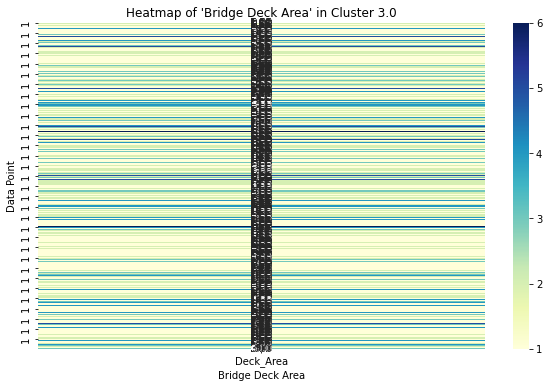

In [16]:
import seaborn as sns

# Find the cluster with the highest performance score
highest_score_cluster = X_clustered_sorted.iloc[0]['cluster']

# Filter the data to select only the data points from the cluster with the highest score
highest_score_data = X_clustered[X_clustered['cluster'] == highest_score_cluster]

# Create a heatmap of 'Bridge Deck Area' within the cluster with the highest performance score
plt.figure(figsize=(10, 6))
sns.heatmap(highest_score_data[['Deck_Area']], cmap='YlGnBu', annot=True, fmt=".2f")
plt.title(f"Heatmap of 'Bridge Deck Area' in Cluster {highest_score_cluster}")
plt.xlabel("Bridge Deck Area")
plt.ylabel("Data Point")
plt.show()


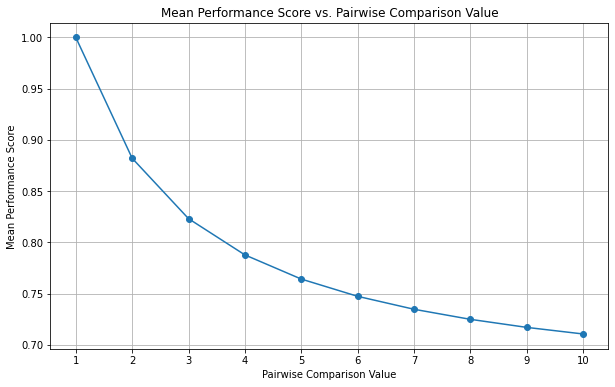

In [2]:
import matplotlib.pyplot as plt

# Define the criteria for AHP
criteria = ['Deck_Area', 'Bridge_Age']
weights = [1, 1]

# Create an empty list to store the performance scores for each comparison value
performance_scores_list = []

# Iterate over the range of comparison values from 1 to 10
for comparison_value in range(1, 11):
    # Calculate the inverse value for the opposite comparison
    inverse_comparison_value = 1 / comparison_value

    # Create a matrix to store the pairwise comparison values for the levels
    comparison_matrix_levels = np.array([[1, comparison_value],
                                         [inverse_comparison_value, 1]])

    # Normalize the matrix to obtain the level weights
    level_weights_deck_area = comparison_matrix_levels.sum(axis=1) / comparison_matrix_levels.sum()
    level_weights_bridge_age = comparison_matrix_levels.sum(axis=0) / comparison_matrix_levels.sum()

    # Calculate the performance scores for each cluster with the current comparison value
    performance_scores_deck_area = X['Deck_Area'].map(dict(enumerate(level_weights_deck_area, start=1)))
    performance_scores_bridge_age = X['Bridge_Age'].map(dict(enumerate(level_weights_bridge_age, start=3)))
    performance_scores = weights[0] * performance_scores_deck_area + weights[1] * performance_scores_bridge_age

    # Add the performance scores to the clustered data
    X_clustered['Performance Score'] = performance_scores

    # Calculate the mean performance score across all clusters
    mean_performance_score = X_clustered['Performance Score'].mean()

    # Append the mean performance score to the list
    performance_scores_list.append(mean_performance_score)

# Create a line plot to visualize the performance scores for different comparison values
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), performance_scores_list, marker='o')
plt.xlabel('Pairwise Comparison Value')
plt.ylabel('Mean Performance Score')
plt.title('Mean Performance Score vs. Pairwise Comparison Value')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


Please provide the pairwise comparison value between level 1 of 'Deck_Area' and level 3 of 'Bridge_Age': 
4


,mainspanmaterial_re,lanes_re,Bridge_Age,Deck_Area,ADT,structure_length,type_of_work,ADTT_Percent,avg_relative_humidity,total_precipitation,cluster,Performance Score
Bridge_condition,,,,,,,,,,,,
1,10,2,3,1,1,1,4,1,2,2,0,2.0
1,8,2,3,1,1,1,4,1,3,3,4,2.0
1,2,2,3,1,1,1,4,3,3,3,3,2.0
1,8,2,3,1,1,1,4,4,3,3,4,2.0
1,8,2,3,1,1,1,4,3,3,3,4,2.0


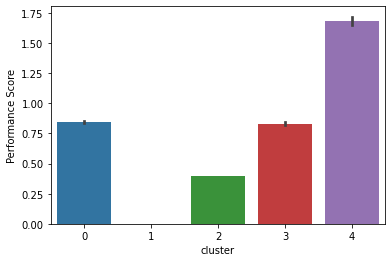

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
from func import *
from scipy.linalg import eig
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# ... (Code for data preprocessing, clustering, and standardization) ...

# ... (Code for data preprocessing, clustering, and standardization) ...

# Define the criteria for AHP
criteria = ['Deck_Area', 'Bridge_Age', 'type_of_work']
weights = [1, 1, 1]

# Calculate the pairwise comparison value between level 1 of 'Deck_Area' and level 3 of 'Bridge_Age'
print("Please provide the pairwise comparison value between level 1 of 'Deck_Area' and level 3 of 'Bridge_Age': ")
comparison_value = float(input())

# Calculate the inverse value for the opposite comparison
inverse_comparison_value = 1 / comparison_value

# Create a matrix to store the pairwise comparison values for the levels
comparison_matrix_levels = np.array([[1, comparison_value],
                                     [inverse_comparison_value, 1]])

# Normalize the matrix to obtain the level weights
level_weights_deck_area = comparison_matrix_levels.sum(axis=1) / comparison_matrix_levels.sum()
level_weights_bridge_age = comparison_matrix_levels.sum(axis=0) / comparison_matrix_levels.sum()

# Calculate the performance scores for each cluster based on 'Deck_Area' and 'Bridge_Age'
performance_scores_deck_area = X['Deck_Area'].map(dict(enumerate(level_weights_deck_area, start=1)))
performance_scores_bridge_age = X['Bridge_Age'].map(dict(enumerate(level_weights_bridge_age, start=3)))

# Calculate the performance scores for 'type_of_work' with level 4
# Assume that 'type_of_work' is a categorical variable with levels 1 to 4 (where level 4 is used)
level_weights_type_of_work = [0, 0, 0, 1]  # Assign 1 to level 4 and 0 to other levels
performance_scores_type_of_work = X['type_of_work'].map(dict(enumerate(level_weights_type_of_work, start=1)))

# Combine the performance scores for all criteria using the defined weights
performance_scores = (
    weights[0] * performance_scores_deck_area +
    weights[1] * performance_scores_bridge_age +
    weights[2] * performance_scores_type_of_work
)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Sort the clusters based on the performance scores
X_clustered_sorted = X_clustered.sort_values('Performance Score', ascending=False)

# Visualize the performance scores for each cluster
sns.barplot(x='cluster', y='Performance Score', data=X_clustered_sorted)

# Show the sorted clustered data
X_clustered_sorted.head()


<AxesSubplot:xlabel='cluster', ylabel='Performance Score'>

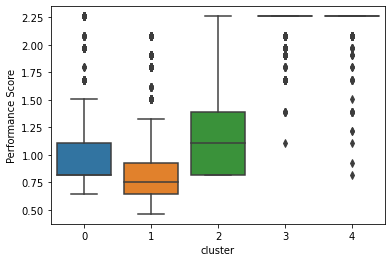

In [65]:
sns.boxplot(x='cluster', y='Performance Score', data=X_clustered_sorted)


<AxesSubplot:xlabel='cluster', ylabel='Performance Score'>

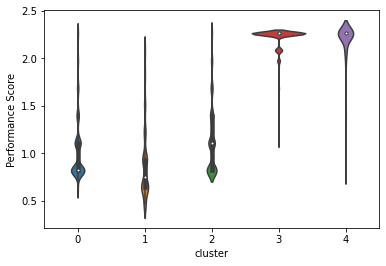

In [66]:
sns.violinplot(x='cluster', y='Performance Score', data=X_clustered_sorted)


In [ ]:
sns.swarmplot(x='cluster', y='Performance Score', data=X_clustered_sorted)


<AxesSubplot:xlabel='type_of_work', ylabel='Performance Score'>

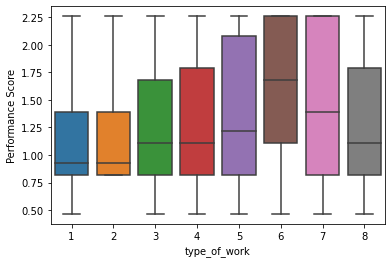

In [3]:
sns.boxplot(x='type_of_work', y='Performance Score', data=X_clustered_sorted)


In [5]:
correlation = X_clustered_sorted['type_of_work'].corr(X_clustered_sorted['Performance Score'])


In [6]:
correlation

0.19785398501023893

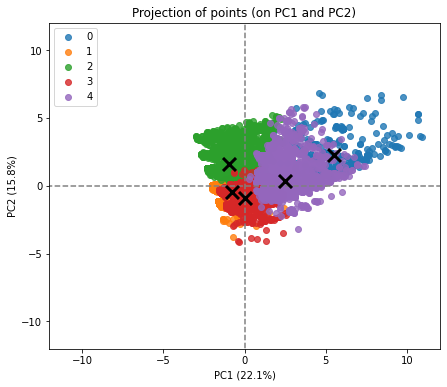

In [19]:
import numpy as np
import pandas as pd
from func import*

X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')

X = X.drop (["mainspandesign_re"],axis=1)

# Import the sklearn function
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled


from sklearn.cluster import KMeans

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to:
clusters =  kmeans.predict(X_scaled)

# Add cluster number to the original data
X_scaled_clustered = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
X_scaled_clustered['cluster'] = clusters

X_scaled_clustered.head()

from sklearn.decomposition import PCA

# Create a PCA model to reduce our data to 2 dimensions for visualisation
pca = PCA(n_components=2)
pca.fit(X_scaled)

# Transfor the scaled data to the new PCA space
X_reduced = pca.transform(X_scaled)

# Convert to a data frame
X_reduceddf = pd.DataFrame(X_reduced, index=X.index, columns=['PC1','PC2'])
X_reduceddf['cluster'] = clusters
X_reduceddf.head()

centres_reduced = pca.transform(kmeans.cluster_centers_)

display_factorial_planes(X_reduced, 2, pca, [(0,1)], illustrative_var = clusters, alpha = 0.8)
plt.scatter(centres_reduced[:, 0], centres_reduced[:, 1],
            marker='x', s=169, linewidths=3,
            color='k', zorder=10)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

X_clustered.head()

category = pd.cut(X_clustered.mainspanmaterial_re,bins = [0,1,2,3,4,5,6,7,8,9,10],
                  labels=['Aluminium','Concrete','Concrete Continuous','Masonry','Other',"Prestressed concrete",
                          "Prestressed continuous","steel","steelcontinuous","timber"])


category1 = pd.cut(X_clustered.lanes_re,bins = [0,1,2,3,4],
                   labels=['One Lane','Two Lanes','Three Lanes','More than Three'])

category2 = pd.cut(X_clustered.Bridge_Age,bins = [0,1,2,3],
                   labels=['0 to 25','26 to 50','more than 50'])

category3 = pd.cut(X_clustered.Deck_Area,bins = [0,1,2,3,4,5,6],
                   labels=['0 to 1000', '1000 to 2000','2000 to 3000','4000 to 5000','5000 to 6000','more than 6000'])

category4 = pd.cut(X_clustered.ADT,bins = [0,1,2,3,4],
                   labels=['0 to 50k','50k to 100k','100k-200k','more than 200k'])

category5 = pd.cut(X_clustered.structure_length,bins = [0,1,2,3,4,5,6],
                   labels=['0 to 200','200 to 500','500 to 1000','1000 to 3000','3000 to 5000','more than 5000'])

category6 = pd.cut(X_clustered.type_of_work,bins = [0,1,2,3,4,5,6,7,8],
                   labels=['replace-load carrying capacity','replace-relocation','widen','widen-deck replace',
                           'rehab-deterioration','rehad-widen','deck replace','structural work'])

category7 = pd.cut(X_clustered.ADTT_Percent,bins = [0,1,2,3,4],
                   labels=['1%-2%','2%-3%','3%-5%','greater than 5%'])

category8 = pd.cut(X_clustered.avg_relative_humidity,bins = [0,1,2,3],
                   labels=['0-50%','50%-75%','more than 75%'])

category9 = pd.cut(X_clustered.total_precipitation,bins = [0,1,2,3,4,5],
                   labels=['0-500','500-1000','1000-2000','2000-3000','more than 3000'])

X_clustered.insert(1,'Construction_Material',category)
X_clustered.insert(2,'Number of Lanes',category1)
X_clustered.insert(3,'Bridge Age',category2)
X_clustered.insert(4,'Deck Area',category3)
X_clustered.insert(5,'Average_Daily_Traffic',category4)
X_clustered.insert(6,'Structure_Length',category5)
X_clustered.insert(7,'Work_Done',category6)
X_clustered.insert(8,'Truck_Percent',category7)
X_clustered.insert(9,'Avg_Relative_Humidity',category8)
X_clustered.insert(10,'Total_Precipitation',category9)

X_clustered.to_csv('C:/Users/Elniajo/Documents/Cluster Analysis/NBI_Results_GPT.csv')

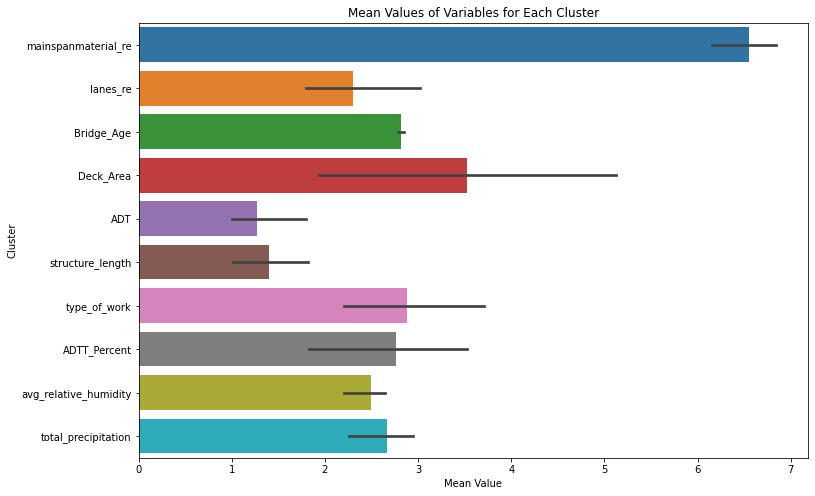

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Calculate the mean values of each variable for each cluster
cluster_means = X_clustered.groupby('cluster').mean()

# Plot the mean values for each variable
plt.figure(figsize=(12, 8))
sns.barplot(data=cluster_means, orient='h')
plt.xlabel('Mean Value')
plt.ylabel('Cluster')
plt.title('Mean Values of Variables for Each Cluster')
plt.show()


C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\ipykernel_launcher.py:25: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\ipykernel_launcher.py:25: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Datas

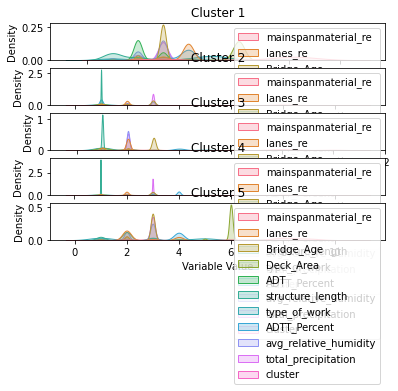

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Iterate over each cluster
for cluster in range(num_clusters):
    # Create a subplot for the current cluster
    plt.subplot(num_clusters, 1, cluster + 1)
    
    # Select the data points belonging to the current cluster
    cluster_data = X_clustered[X_clustered['cluster'] == cluster]
    
    # Plot the variables for the current cluster
    sns.kdeplot(data=cluster_data, fill=True)
    
    # Add labels and title to the subplot
    plt.xlabel('Variable Value')
    plt.ylabel('Density')
    plt.title(f'Cluster {cluster+1}')
    
    # Adjust the spacing between subplots
    plt.tight_layout()

# Display the plot
plt.show()


C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\seaborn\distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site

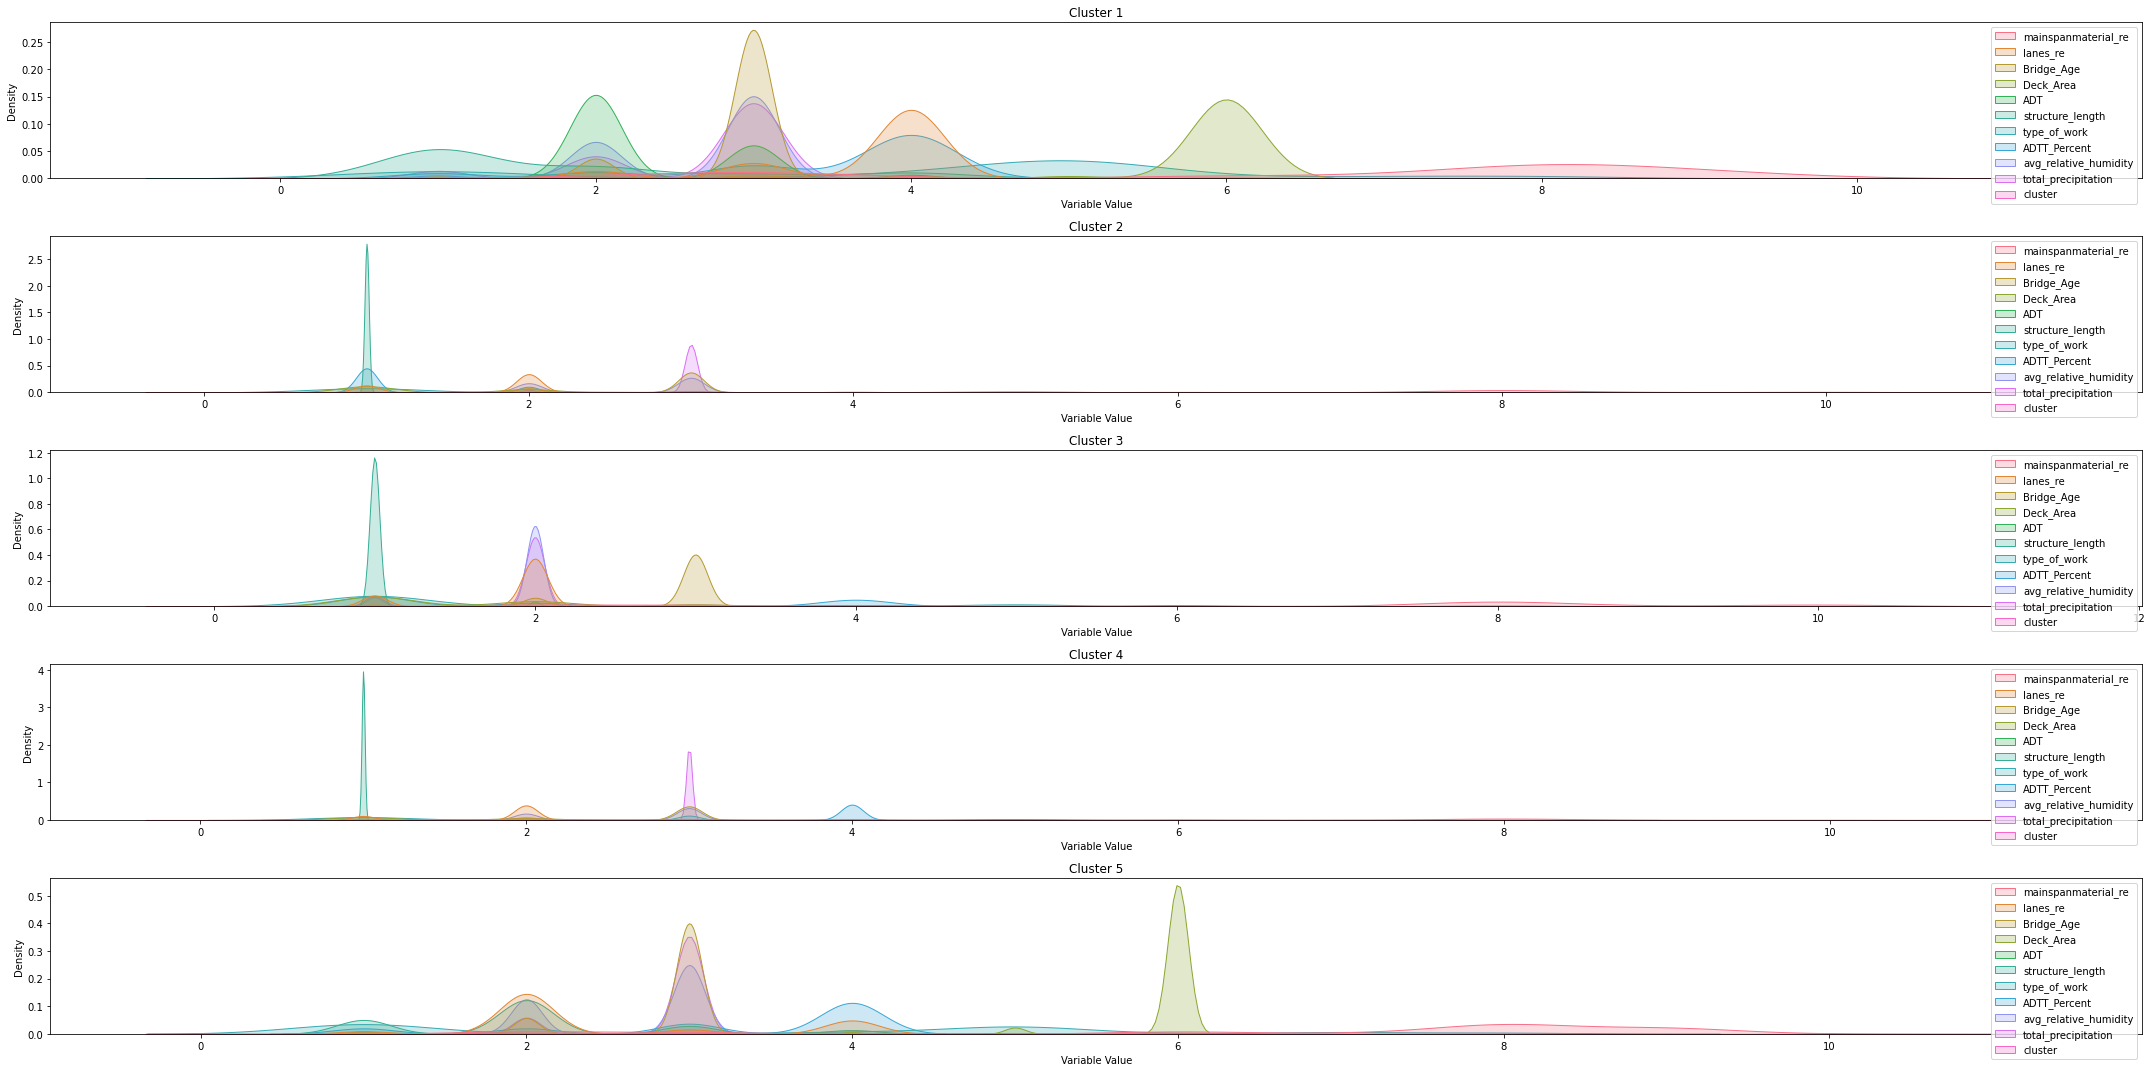

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(30, 15))

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Iterate over each cluster
for cluster in range(num_clusters):
    # Create a subplot for the current cluster
    plt.subplot(num_clusters, 1, cluster + 1)
    
    # Select the data points belonging to the current cluster
    cluster_data = X_clustered[X_clustered['cluster'] == cluster]
    
    # Plot the variables for the current cluster
    sns.kdeplot(data=cluster_data, fill=True)
    
    # Add labels and title to the subplot
    plt.xlabel('Variable Value')
    plt.ylabel('Density')
    plt.title(f'Cluster {cluster+1}')
    
    # Adjust the spacing between subplots
    plt.tight_layout()

# Display the plot
plt.show()


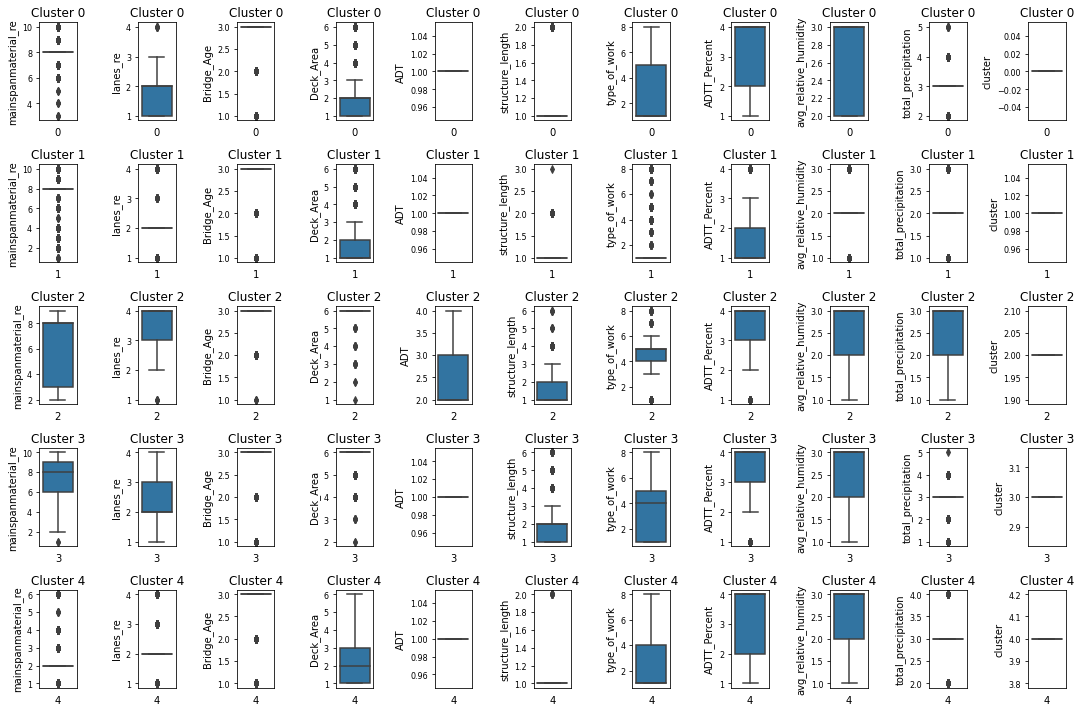

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read the data and perform clustering
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Perform clustering using K-means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(init='random', n_clusters=5, n_init=10)
kmeans.fit(X_scaled)

clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Plot box plots for each variable within each cluster
num_clusters = len(X_clustered['cluster'].unique())
num_variables = len(X.columns)

# Create subplots for each variable
fig, axes = plt.subplots(num_clusters, num_variables, figsize=(15, 10))

for cluster in range(num_clusters):
    cluster_data = X_clustered[X_clustered['cluster'] == cluster]
    
    for i, variable in enumerate(X.columns):
        ax = axes[cluster, i]
        sns.boxplot(x='cluster', y=variable, data=cluster_data, ax=ax)
        ax.set_xlabel('')
        ax.set_ylabel(variable)
        ax.set_title(f'Cluster {cluster}')
        ax.tick_params(axis='x', bottom=False)
        ax.tick_params(axis='y', labelsize=8)
        
# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()


In [29]:
import numpy as np
import pandas as pd
from func import *
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for MOGA
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Run the MOGA optimization algorithm using a suitable library (e.g., Platypus)
# Set up the optimization problem with objectives and decision variables
problem = MOGAProblem(costs)

# Run the optimization algorithm
pareto_front = problem.optimize()

# Visualize the Pareto front
pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
sns.scatterplot(data=pareto_df, x='Performance Score', y='Cost')
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


NameError: name 'MOGAProblem' is not defined

In [32]:
pip install pygmo

Note: you may need to restart the kernel to use updated packages.


ERROR: File "setup.py" not found for legacy project pygmo from https://files.pythonhosted.org/packages/e2/12/090ba61479f60d5177a0048736d09dc028b2d65063ed44cb952df506336f/pygmo-v2.19.0.tar.gz#sha256=0d78646a78ee073d97532a10156e62c4553d3e88121bbcb364c6489b52345091.


In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pygmo as pg

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
def objective_function(x):
    return [-eligible_cluster['Performance Score'], x[0]]  # Negative sign to maximize performance score

# Define the bounds for the decision variables
bounds = [(0, np.inf)]  # Assuming a non-negative cost variable

# Create the optimization problem
prob = pg.problem(pg.zdt(zdt_id=1, param=1, m=2))

# Create the optimization algorithm (NSGA-II in this case)
algorithm = pg.algorithm(pg.nsga2(gen=100))

# Create an empty population to store the solutions
population = pg.population(prob)

# Run the optimization algorithm
algorithm.set_verbosity(1)
population = algorithm.evolve(population)

# Extract the Pareto front solutions
pareto_front = population.get_f()

# Extract the decision variables of the Pareto front solutions
pareto_variables = population.get_x()

# Visualize the Pareto front
pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
sns.scatterplot(data=pareto_df, x='Performance Score', y='Cost')
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


ModuleNotFoundError: No module named 'pygmo'

In [33]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from deap import algorithms, base, creator, tools

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
creator.create("FitnessMin", base.Fitness, weights=(-1.0, -1.0))  # Minimize both objectives
creator.create("Individual", np.ndarray, fitness=creator.FitnessMin)

def evaluate(individual):
    return (-eligible_cluster['Performance Score'], individual[0]),

toolbox = base.Toolbox()
toolbox.register("evaluate", evaluate)

# Define the bounds for the decision variables
toolbox.register("attr_float", np.random.uniform, 0, np.inf)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_float, n=1)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Define the genetic operators
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutUniformFloat, low=0, up=np.inf, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

# Create an initial population
population = toolbox.population(n=50)

# Run the optimization algorithm
NGEN = 100
CXPB = 0.9
MUTPB = 0.1

for gen in range(NGEN):
    offspring = algorithms.varAnd(population, toolbox, cxpb=CXPB, mutpb=MUTPB)
    fits = toolbox.map(toolbox.evaluate, offspring)
    for fit, ind in zip(fits, offspring):
        ind.fitness.values = fit
    population = toolbox.select(offspring, k=len(population))

# Extract the Pareto front solutions
pareto_front = [ind.fitness.values for ind in population]

# Extract the decision variables of the Pareto front solutions
pareto_variables = [ind[0] for ind in population]

# Visualize the Pareto front
import matplotlib.pyplot as plt

pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
plt.scatter(pareto_df['Performance Score'], pareto_df['Cost'])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


AttributeError: module 'deap.tools' has no attribute 'mutUniformFloat'

In [44]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from deap import algorithms, base, creator, tools

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
creator.create("FitnessMin", base.Fitness, weights=(-1.0, -1.0))  # Minimize both objectives
creator.create("Individual", np.ndarray, fitness=creator.FitnessMin)

def evaluate(individual):
    return (-eligible_cluster['Performance Score'], individual[0]),

toolbox = base.Toolbox()
toolbox.register("evaluate", evaluate)

# Define the bounds for the decision variables
lower_bound = 0
upper_bound = np.inf
toolbox.register("attr_float", np.random.uniform, lower_bound, upper_bound)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_float, n=1)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Define the genetic operators
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutPolynomialBounded, eta=20, low=lower_bound, up=upper_bound, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

# Create an initial population
population = toolbox.population(n=50)

# Run the optimization algorithm
NGEN = 100
CXPB = 0.9
MUTPB = 0.1

for gen in range(NGEN):
    offspring = algorithms.varAnd(population, toolbox, cxpb=CXPB, mutpb=MUTPB)
    fits = toolbox.map(toolbox.evaluate, offspring)
    for fit, ind in zip(fits, offspring):
        ind.fitness.values = fit
    population = toolbox.select(offspring, k=len(population))

# Extract the Pareto front solutions
pareto_front = [ind.fitness.values for ind in population]

# Extract the decision variables of the Pareto front solutions
pareto_variables = [ind[0] for ind in pareto_front]

# Visualize the Pareto front
import matplotlib.pyplot as plt

pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
plt.scatter(pareto_df['Performance Score'], pareto_df['Cost'])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\deap\creator.py:141: RuntimeWarning: A class named 'FitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  RuntimeWarning)
C:\Users\Elniajo\anaconda3\envs\jupyter\lib\site-packages\deap\creator.py:141: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  RuntimeWarning)


OverflowError: Range exceeds valid bounds

In [39]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from deap import algorithms, base, creator, tools

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Categorical variables
categorical_variables = ['mainspanmaterial_re', 'lanes_re', 'Bridge_Age', 'Deck_Area', 'ADT',
                         'structure_length', 'type_of_work', 'ADTT_Percent', 'avg_relative_humidity',
                         'total_precipitation']

# One-hot encode the categorical variables
X_encoded = pd.get_dummies(X, columns=categorical_variables)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X_encoded, columns=X_encoded.columns, index=X_encoded.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['type_of_work']  # Replace 'Cost' with the actual column name

# Define the optimization problem
creator.create("FitnessMin", base.Fitness, weights=(-1.0, -1.0))  # Minimize both objectives
creator.create("Individual", np.ndarray, fitness=creator.FitnessMin)

def evaluate(individual):
    return (-eligible_cluster['Performance Score'], individual[0]),

toolbox = base.Toolbox()
toolbox.register("evaluate", evaluate)

# Define the bounds for the decision variables
lower_bound = 0
upper_bound = np.inf
toolbox.register("attr_float", np.random.uniform, lower_bound, upper_bound)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_float, n=1)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Define the genetic operators
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutPolynomialBounded, eta=20, low=lower_bound, up=upper_bound, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

# Create an initial population
population = toolbox.population(n=50)

# Run the optimization algorithm
NGEN = 100
CXPB = 0.9
MUTPB = 0.1

for gen in range(NGEN):
    offspring = algorithms.varAnd(population, toolbox, cxpb=CXPB, mutpb=MUTPB)
    fits = toolbox.map(toolbox.evaluate, offspring)
    for fit, ind in zip(fits, offspring):
        ind.fitness.values = fit
    population = toolbox.select(offspring, k=len(population))

# Extract the Pareto front solutions
pareto_front = [ind.fitness.values for ind in population]

# Extract the decision variables of the Pareto front solutions
pareto_variables = [ind[0] for ind in pareto_front]

# Visualize the Pareto front
import matplotlib.pyplot as plt

pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
plt.scatter(pareto_df['Performance Score'], pareto_df['Cost'])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


KeyError: "None of [Index(['total_precipitation', 'lane_re'], dtype='object')] are in the [columns]"

In [46]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from deap import algorithms, base, creator, tools

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Categorical variables
categorical_variables = ['lanes_re', 'Bridge_Age']

# One-hot encode the categorical variables
X_encoded = pd.get_dummies(X, columns=categorical_variables)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X_encoded, columns=X_encoded.columns, index=X_encoded.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Bridge_Age', 'Deck_Area']
weights = [0.7, 0.3]

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
creator.create("FitnessMin", base.Fitness, weights=(-1.0, -1.0))  # Minimize both objectives
creator.create("Individual", np.ndarray, fitness=creator.FitnessMin)

def evaluate(individual):
    return (-eligible_cluster['Performance Score'], individual[0]),

toolbox = base.Toolbox()
toolbox.register("evaluate", evaluate)

# Define the bounds for the decision variables
lower_bound = 0
upper_bound = np.inf
toolbox.register("attr_float", np.random.uniform, lower_bound, upper_bound)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_float, n=1)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Define the genetic operators
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutPolynomialBounded, eta=20, low=lower_bound, up=upper_bound, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

# Create an initial population
population = toolbox.population(n=50)

# Run the optimization algorithm
NGEN = 100
CXPB = 0.9
MUTPB = 0.1

for gen in range(NGEN):
    offspring = algorithms.varAnd(population, toolbox, cxpb=CXPB, mutpb=MUTPB)
    fits = toolbox.map(toolbox.evaluate, offspring)
    for fit, ind in zip(fits, offspring):
        ind.fitness.values = fit
    population = toolbox.select(offspring, k=len(population))

# Extract the Pareto front solutions
pareto_front = [ind.fitness.values for ind in population]

# Extract the decision variables of the Pareto front solutions
pareto_variables = [ind[0] for ind in pareto_front]

# Visualize the Pareto front
import matplotlib.pyplot as plt

pareto_df = pd.DataFrame(pareto_front, columns=['Performance Score', 'Cost'])
plt.scatter(pareto_df['Performance Score'], pareto_df['Cost'])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


KeyError: "['Bridge_Age'] not in index"

In [54]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from platypus import NSGAII, Problem, Real

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [-1, -1]  # Minimize both criteria

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
class ProjectOptimization(Problem):
    def __init__(self):
        super().__init__(2, 1)  # Two decision variables and one objective

        # Set the bounds for the decision variables
        self.types[:] = Real(0, np.inf)

    def evaluate(self, solution):
        performance_score = -eligible_cluster['Performance Score']
        cost = solution.variables[0]

        # Set the objective values
        solution.objectives[:] = [performance_score, cost]

        # Set the constraint violation (always 0 in this case)
        solution.constraints[:] = 0

problem = ProjectOptimization()

# Run the optimization algorithm
algorithm = NSGAII(problem)
algorithm.run(100)

# Extract the Pareto front solutions
pareto_front = algorithm.result

# Extract the decision variables and objective values of the Pareto front solutions
pareto_variables = [solution.variables for solution in pareto_front]
pareto_objectives = [solution.objectives for solution in pareto_front]

# Visualize the Pareto front
import matplotlib.pyplot as plt

pareto_df = pd.DataFrame(pareto_objectives, columns=['Performance Score', 'Cost'])
plt.scatter(pareto_df['Performance Score'], pareto_df['Cost'])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


ModuleNotFoundError: No module named 'platypus'

In [56]:
pip install pymoo

Note: you may need to restart the kernel to use updated packages.


In [57]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pymoo.model.problem import Problem
from pymoo.algorithms.nsga2 import NSGA2
from pymoo.factory import get_performance_indicator
from pymoo.optimize import minimize

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [-1, -1]  # Minimize both criteria

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
class ProjectOptimization(Problem):
    def __init__(self):
        super().__init__(n_var=1, n_obj=2, n_constr=0, xl=np.array([0]), xu=np.array([np.inf]))

    def _evaluate(self, x, out, *args, **kwargs):
        performance_score = -eligible_cluster['Performance Score']
        cost = x[:, 0]

        out["F"] = np.column_stack((performance_score, cost))

problem = ProjectOptimization()

# Set up the NSGA-II algorithm
algorithm = NSGA2(pop_size=100)

# Optimize the problem
res = minimize(problem, algorithm, ("n_gen", 100))

# Extract the Pareto front solutions
pareto_front = res.F

# Visualize the Pareto front
import matplotlib.pyplot as plt

plt.scatter(pareto_front[:, 0], pareto_front[:, 1])
plt.xlabel('Performance Score')
plt.ylabel('Cost')
plt.title('Pareto Front')
plt.show()


ModuleNotFoundError: No module named 'pymoo.model'

In [63]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pymoo.model.problem import Problem
from pymoo.algorithms.nsga2 import NSGA2
from pymoo.factory import get_performance_indicator, get_termination
from pymoo.optimize import minimize
from pymoo.visualization.scatter import Scatter

# Read the data
X = pd.read_csv('NBI_model_only2.csv', index_col='Bridge_condition')
X = X.drop(["mainspandesign_re"], axis=1)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a k-means clustering model
kmeans = KMeans(init='random', n_clusters=5, n_init=10)

# Fit the data to the model
kmeans.fit(X_scaled)

# Determine which clusters each data point belongs to
clusters = kmeans.predict(X_scaled)

# Add cluster number to the original data
X_clustered = pd.DataFrame(X, columns=X.columns, index=X.index)
X_clustered['cluster'] = clusters

# Define the criteria for multi-objective optimization
criteria = ['Deck_Area', 'Bridge_Age']
weights = [-1, -1]  # Minimize both criteria

# Calculate the performance scores for each cluster
performance_scores = np.dot(X_clustered[criteria], weights)

# Add the performance scores to the clustered data
X_clustered['Performance Score'] = performance_scores

# Select the cluster with the highest performance score
eligible_cluster = X_clustered.loc[X_clustered['Performance Score'].idxmax()]

# Assuming 'Cost' is a column in the dataset representing the cost of each project
costs = eligible_cluster['Deck_Area']  # Replace 'Cost' with the actual column name

# Define the optimization problem
class ProjectOptimization(Problem):
    def __init__(self):
        super().__init__(n_var=1, n_obj=2, n_constr=0, xl=np.array([0]), xu=np.array([np.inf]))

    def _evaluate(self, x, out, *args, **kwargs):
        performance_score = -eligible_cluster['Performance Score']
        cost = x[:, 0]

        out["F"] = np.column_stack((performance_score, cost))

problem = ProjectOptimization()

# Set up the NSGA-II algorithm
algorithm = NSGA2(pop_size=100)

# Set up the termination criterion
termination = get_termination("n_gen", 100)

# Optimize the problem
res = minimize(problem, algorithm, termination, seed=1)

# Extract the Pareto front solutions
pareto_front = res.F

# Visualize the Pareto front
plot = Scatter()
plot.add(pareto_front, color="red")
plot.show()



ModuleNotFoundError: No module named 'pymoo.algorithms.nsga2'

In [59]:
pip install pymoo